# Kết quả chính: MNIST
MultinomialNB, Softmax và MLP tự cài đặt NumPy; Random Forest dùng scikit-learn.
Các mô hình nằm trong `src/mnist_project/models.py`.
Đặt `RUN_EXPERIMENT=True` để huấn luyện lại bốn mô hình.

In [1]:
# Tích hợp và chạy thí nghiệm.
from pathlib import Path
import sys, os

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Image

RUN_EXPERIMENT = False
if RUN_EXPERIMENT or not (ROOT / "result/full/metrics.csv").exists():
    from mnist_project.experiment import run

    run("full", baseline=True)


## Cấu hình và dữ liệu
Seed 42; chia phân tầng từ 60.000 ảnh training chính thức. Tập test 10.000 ảnh được giữ riêng.

{
  "mode": "full",
  "seed": 42,
  "epochs_lr": 100,
  "epochs_mlp": 100,
  "early_stopping": true,
  "patience": 10,
  "min_delta": 0.0001,
  "restore_best_weights": true,
  "hidden": [
    128,
    64
  ],
  "mlp_lr": 0.7,
  "nb_alpha_grid": [
    0.1,
    1.0,
    10.0
  ],
  "mlp_hidden_1_grid": [
    64,
    128,
    256
  ],
  "selection_metric": "validation_f1_macro",
  "trees": 40,
  "nb_alpha": 0.1,
  "max_features": 28,
  "split_implementation": "sklearn.model_selection.train_test_split",
  "forest_n_jobs": -1,
  "forest_implementation": "sklearn.ensemble.RandomForestClassifier",
  "depth": 14,
  "n": {
    "train": 54000,
    "validation": 6000,
    "test": 10000
  },
  "python": "3.13.5",
  "platform": "Windows-11-10.0.26300-SP0",
  "processor": "Intel64 Family 6 Model 154 Stepping 3, GenuineIntel",
  "numpy": "2.5.4",
  "sha256": "731c5ac602752760c8e48fbffcf8c3b850d9dc2a2aedcf2cc48468fc17b673d1",
  "chosen_lr": 0.5,
  "learning_rate_grid": [
    0.05,
    0.1,
    0.3,
  

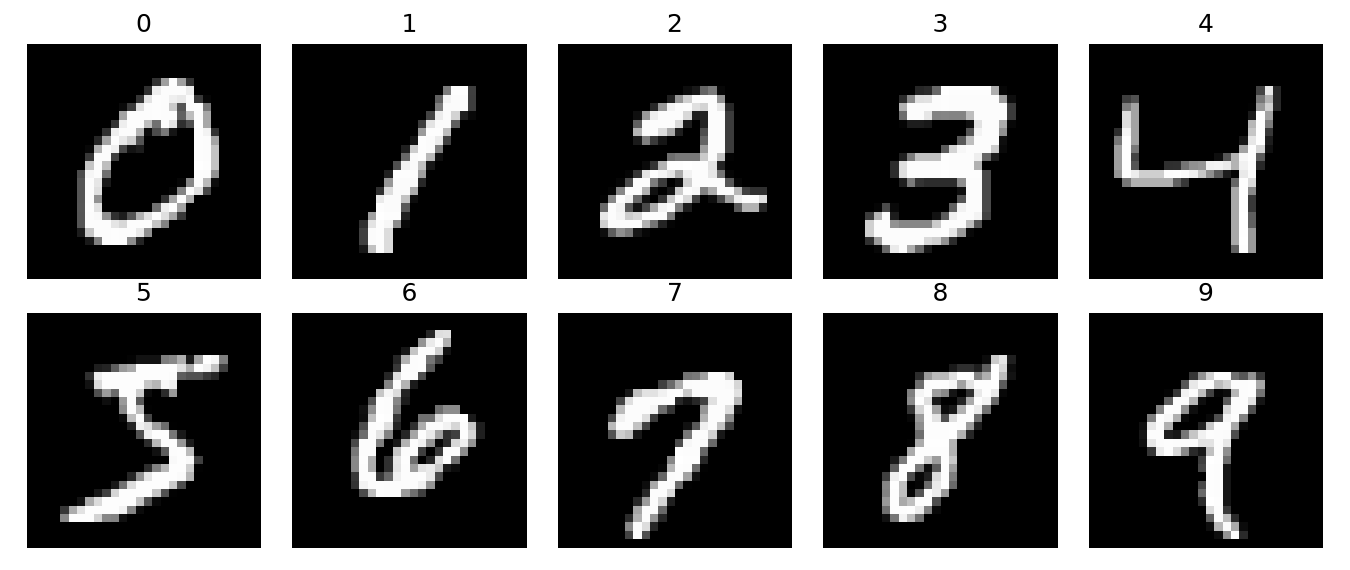

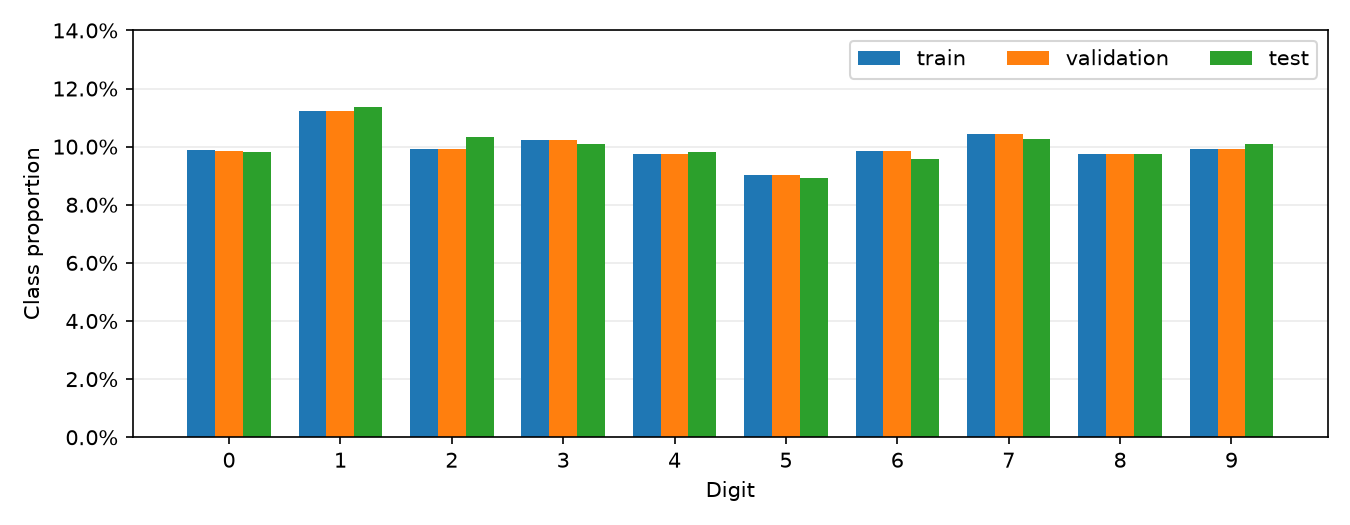

In [2]:
print((ROOT / "result/full/config.json").read_text())
display(Image(filename=str(ROOT / "result/figures/full/samples.png")))
display(Image(filename=str(ROOT / "result/figures/full/distribution.png")))


## Bảng đầy đủ train / validation / test

In [3]:
metrics = pd.read_csv(ROOT / "result/full/metrics.csv")
display(metrics.round(5))


,model,split,n,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,predict_ms_per_image
0,MultinomialNB,train,54000,0.82431,0.83122,0.82126,0.82298,0.28276,0.19567,0.00362
1,MultinomialNB,validation,6000,0.82433,0.83305,0.82148,0.82330,0.28276,0.02233,0.00372
2,MultinomialNB,test,10000,0.83560,0.84286,0.83247,0.83412,0.28276,0.03605,0.00360
3,Softmax LR,train,54000,0.93063,0.92984,0.92977,0.92972,3.80385,0.02989,0.00055
4,Softmax LR,validation,6000,0.92317,0.92252,0.92248,0.92238,3.80385,0.00266,0.00044
5,Softmax LR,test,10000,0.92290,0.92192,0.92195,0.92178,3.80385,0.00458,0.00046
6,MLP,train,54000,0.99981,0.99982,0.99982,0.99982,11.52466,0.09894,0.00183
7,MLP,validation,6000,0.97917,0.97909,0.97893,0.97899,11.52466,0.01008,0.00168
8,MLP,test,10000,0.97810,0.97802,0.97789,0.97793,11.52466,0.01619,0.00162
9,Random Forest,train,54000,0.99317,0.99328,0.99316,0.99321,2.00317,0.17229,0.00319


## So sánh bốn mô hình
Cùng split 54.000/6.000/10.000, pixel chuẩn hóa [0,1], seed 42.
Random Forest: 40 cây, sâu tối đa 14, 28 đặc trưng mỗi nút, lá tối thiểu 2 mẫu.
Softmax và MLP dùng tối đa 100 epoch, Early Stopping trên validation.

,split,n,accuracy,precision_macro,recall_macro,f1_macro,train_seconds,predict_seconds,predict_ms_per_image
model,,,,,,,,,
MultinomialNB,test,10000,0.8356,0.84286,0.83247,0.83412,0.28276,0.03605,0.00360
Softmax LR,test,10000,0.9229,0.92192,0.92195,0.92178,3.80385,0.00458,0.00046
MLP,test,10000,0.9781,0.97802,0.97789,0.97793,11.52466,0.01619,0.00162
Random Forest,test,10000,0.9597,0.95950,0.95924,0.95932,2.00317,0.04091,0.00409


Một lần chạy seed 42; chưa đánh giá độ ổn định qua nhiều seed.


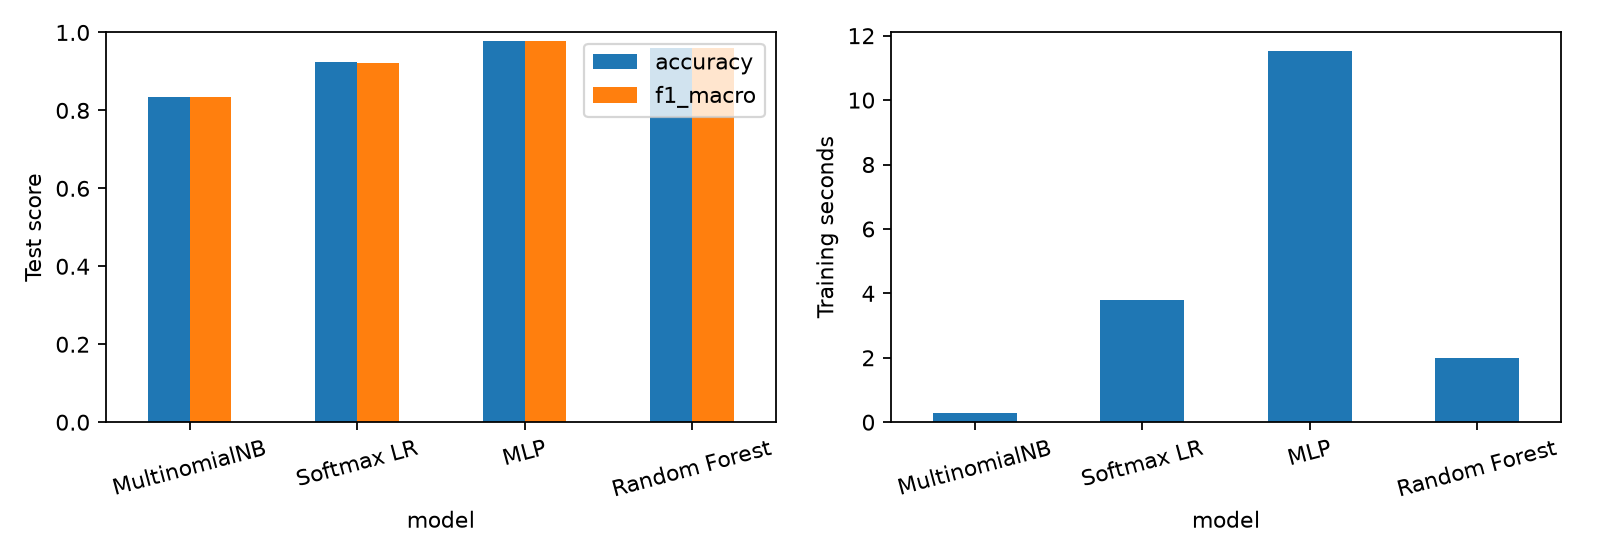

In [4]:
test_comparison = metrics[metrics.split == "test"].set_index("model")
display(test_comparison.round(5))
print("Một lần chạy seed 42; chưa đánh giá độ ổn định qua nhiều seed.")
display(Image(filename=str(ROOT / "result/figures/full/comparison.png")))


## Đối chiếu scikit-learn trên cùng dữ liệu
Baseline được chạy lại cùng đợt FULL. Ngân sách và bộ tối ưu có thể khác mô hình chính; bảng này báo cáo F1 validation. Thông tin cảnh báo của lượt chạy được ghi trong `result/full/baseline_provenance.json`.

In [5]:
display(pd.read_csv(ROOT / "result/full/baseline.csv"))


,model,validation_f1_macro,train_seconds
0,MultinomialNB,0.823298,0.249368
1,Softmax LR,0.921380,13.183704
2,MLP,0.971402,65.822310
3,Random Forest,0.957229,5.063638


## Khảo sát siêu tham số
Chọn alpha NB, learning rate Softmax và độ rộng lớp ẩn đầu MLP bằng Macro F1 validation. MLP giữ hai lớp ẩn `(value, 64)`. Số giá trị và cấu hình được đọc từ các bảng bên dưới; test không tham gia lựa chọn.

,value,train_seconds,train_accuracy,train_f1_macro,validation_accuracy,validation_f1_macro,alpha
0,0.1,0.328294,0.824315,0.822978,0.824333,0.823298,0.1
1,1.0,0.404827,0.823685,0.822329,0.824000,0.822972,1.0
2,10.0,0.291781,0.821296,0.819895,0.822500,0.821438,10.0


,value,train_seconds,train_accuracy,train_f1_macro,validation_accuracy,validation_f1_macro,hidden_1,hidden_2,lr,epochs_run,best_epoch
0,64,4.453637,0.984463,0.984366,0.970833,0.970584,64,64,0.7,20,10
1,128,10.763726,0.999815,0.999820,0.979167,0.978991,128,64,0.7,31,21
2,256,13.292490,0.998500,0.998511,0.977667,0.977578,256,64,0.7,22,12


,lr,validation_f1_macro,epochs_run,best_epoch
0,0.05,0.918661,100,100
1,0.10,0.920997,100,100
2,0.30,0.920062,65,55
3,0.50,0.922382,38,28
4,0.70,0.922380,38,28
5,1.00,0.918702,20,18


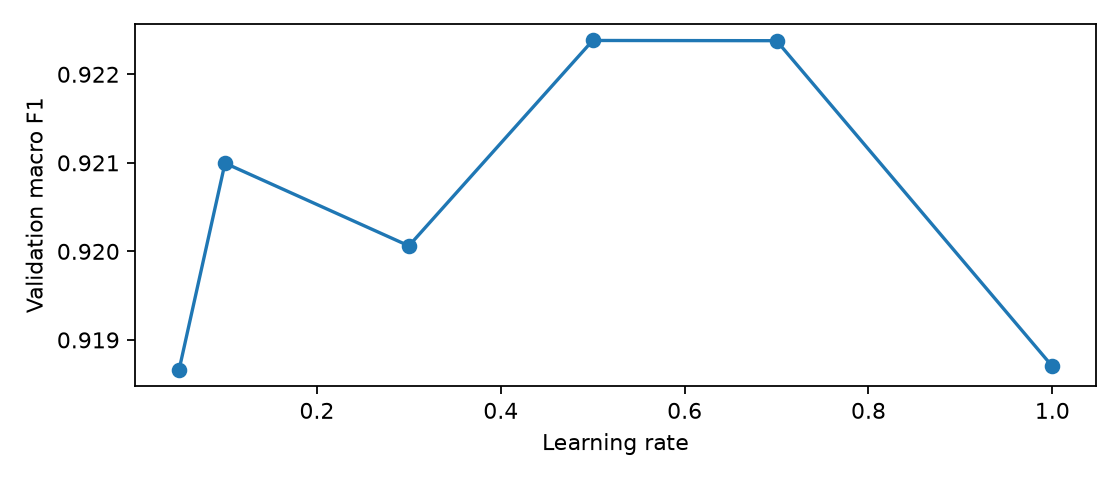

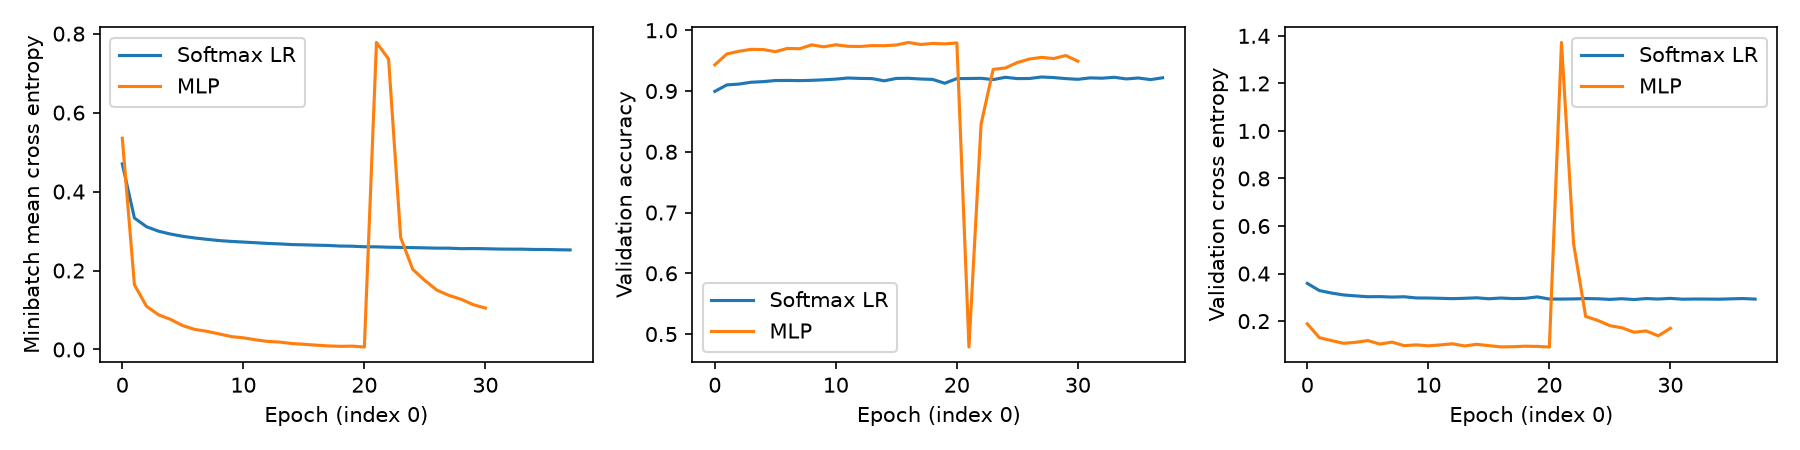

,trees,validation_f1_macro
35,36,0.957454
36,37,0.957601
37,38,0.958128
38,39,0.957784
39,40,0.957229


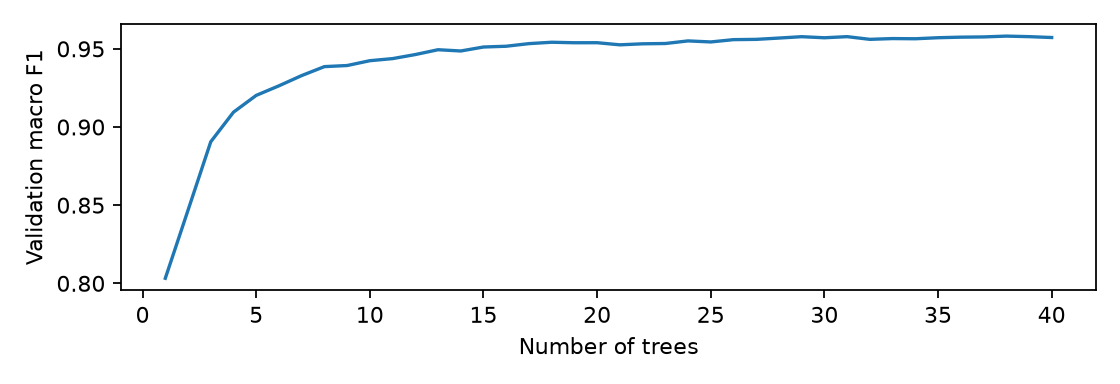

In [6]:
display(pd.read_csv(ROOT / "result/full/nb_alpha_sweep.csv"))
display(pd.read_csv(ROOT / "result/full/mlp_hidden_sweep.csv"))
display(pd.read_csv(ROOT / "result/full/lr_sweep.csv"))
display(Image(filename=str(ROOT / "result/figures/full/lr_sweep.png")))
display(Image(filename=str(ROOT / "result/figures/full/learning.png")))
display(pd.read_csv(ROOT / "result/full/forest_curve.csv").tail())
display(Image(filename=str(ROOT / "result/figures/full/forest_curve.png")))


## Phân tích lỗi
Chọn mô hình theo F1 validation, sau đó mô tả test; không tuning dựa vào ảnh sai.

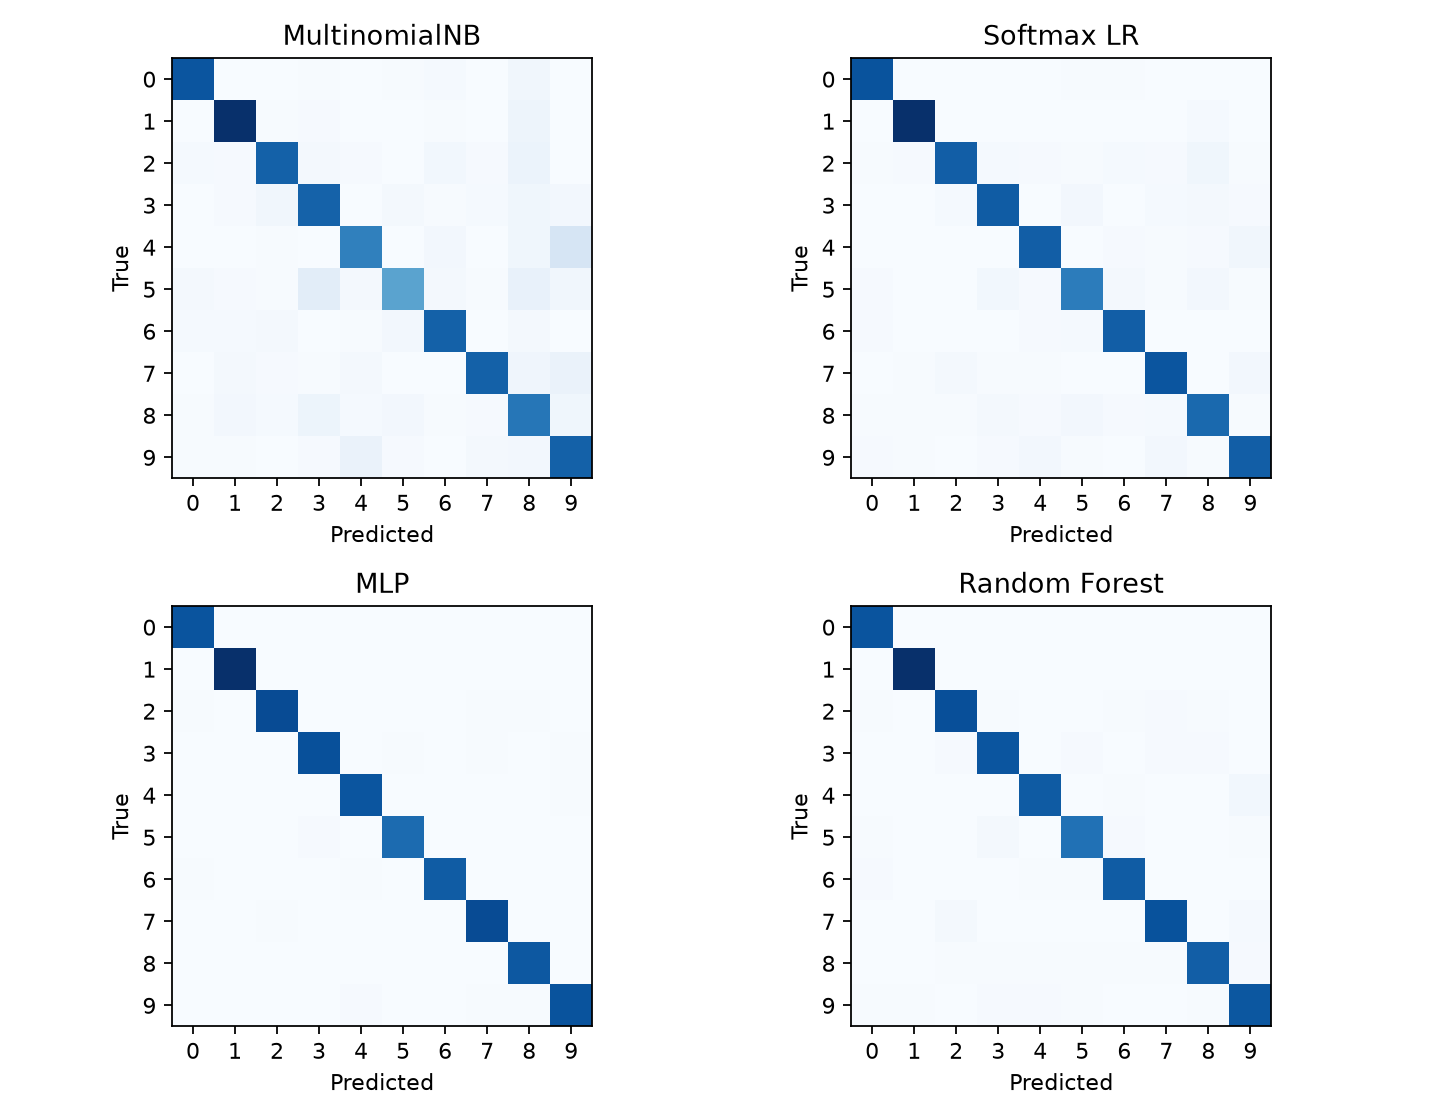

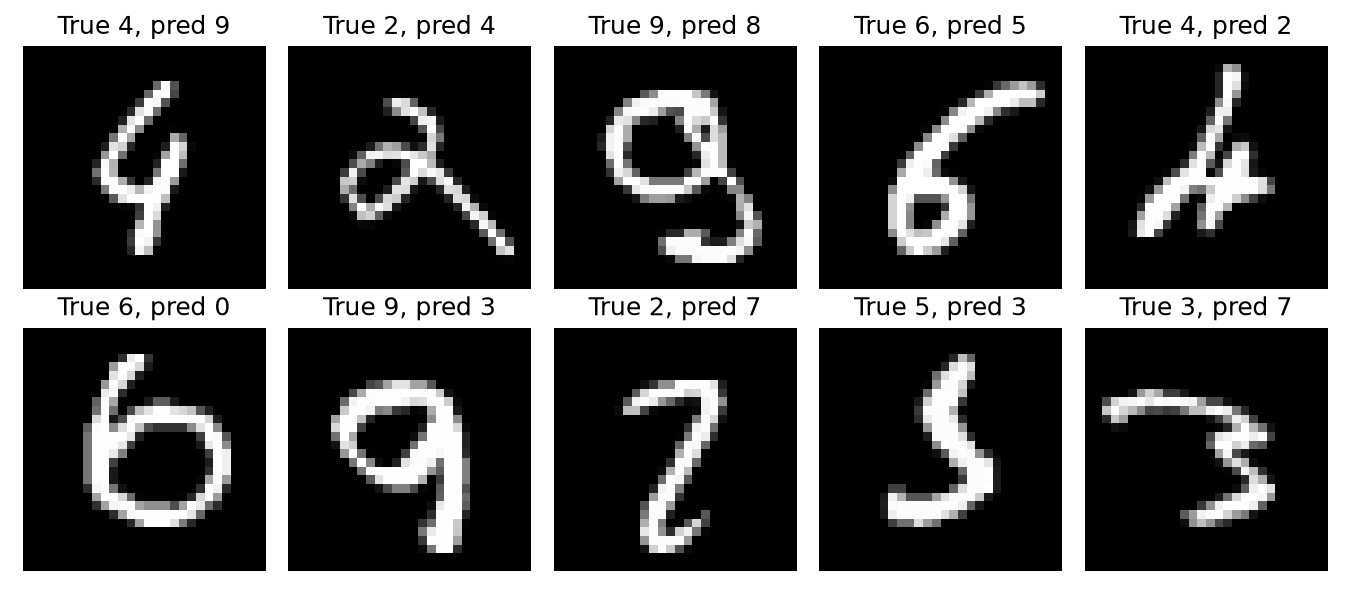

In [7]:
display(Image(filename=str(ROOT / "result/figures/full/confusion.png")))
display(Image(filename=str(ROOT / "result/figures/full/errors.png")))


## EMNIST Digits
Đánh giá cùng trọng số trên MNIST và EMNIST, không huấn luyện lại. Hai tập có chung nguồn gốc NIST; chưa xác minh tính độc lập về mẫu/người viết.

,model,dataset_mnist,n_mnist,accuracy_mnist,precision_macro_mnist,recall_macro_mnist,f1_macro_mnist,dataset_emnist,n_emnist,accuracy_emnist,precision_macro_emnist,recall_macro_emnist,f1_macro_emnist,accuracy_delta_pp,precision_macro_delta_pp,recall_macro_delta_pp,f1_macro_delta_pp
0,MultinomialNB,MNIST,10000,0.8356,0.842865,0.832472,0.834122,EMNIST Digits,40000,0.489050,0.495920,0.489050,0.419423,-34.6550,-34.694439,-34.342228,-41.469968
1,Softmax LR,MNIST,10000,0.9229,0.921916,0.921952,0.921783,EMNIST Digits,40000,0.549650,0.600693,0.549650,0.520607,-37.3250,-32.122340,-37.230192,-40.117577
2,MLP,MNIST,10000,0.9781,0.978016,0.977895,0.977935,EMNIST Digits,40000,0.757625,0.776216,0.757625,0.728827,-22.0475,-20.179981,-22.026960,-24.910743
3,Random Forest,MNIST,10000,0.9597,0.959497,0.959236,0.959323,EMNIST Digits,40000,0.674175,0.672589,0.674175,0.624410,-28.5525,-28.690727,-28.506134,-33.491282


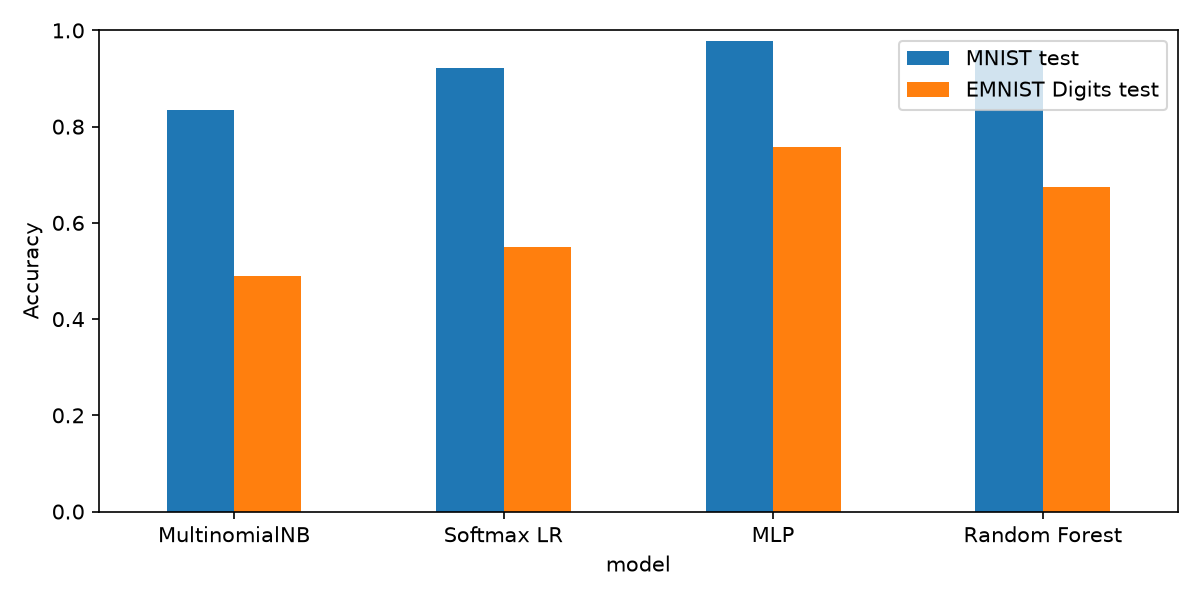

In [8]:
display(pd.read_csv(ROOT / "result/emnist/comparison.csv"))
display(Image(filename=str(ROOT / "result/emnist/comparison.png")))